<a href="https://colab.research.google.com/github/neilbhana/neilbhana-Datascience-GenAI-Submissions/blob/main/Seminar_week_3_titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic Dataset - Exploratory Data Analysis
We will start by importing the necessary libraries, loading the Titanic dataset from a public URL, and examining its fundamental properties.

In [6]:
import pandas as pd
import io
from google.colab import files

# Request file upload
uploaded = files.upload()

# Assuming the file is named 'titanic.csv'
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Display the first few rows
display(df.head())

Saving titanic.csv to titanic.csv


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Dataset Dimensions (Size)
Let's check the size of the dataset (number of rows and columns).

In [8]:
print(f"Dataset Shape: {df.shape}")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

Dataset Shape: (891, 12)
Total Rows: 891
Total Columns: 12


## 2. Column Types and Missing Values
We will inspect the data types of each column to ensure they are loaded correctly, and check for any missing (null) values in the dataset.

In [3]:
# Check info including data types and non-null counts
print("--- Column Types and Non-Null Counts ---")
df.info()

# Detailed count of missing values per column
print("\n--- Missing Values Per Column ---")
missing_vals = df.isnull().sum()
display(missing_vals[missing_vals > 0])

--- Column Types and Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

--- Missing Values Per Column ---


,0
Age,177
Cabin,687
Embarked,2


## 3. Duplicate Records
We will verify if there are any completely duplicate rows in the dataset.

In [10]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


## 4. Summary Statistics
Now we will display the summary statistics for both numeric and categorical features to understand their distributions.

In [11]:
print("--- Numeric Columns Summary ---")
display(df.describe())

print("\n--- Categorical Columns Summary ---")
display(df.describe(include=['O']))

--- Numeric Columns Summary ---


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



--- Categorical Columns Summary ---


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## 5. Survival Rate by Gender
Let's calculate and visualize the survival rate comparing female and male passengers.

Survival Rate by Gender:
      Sex  Survived
0  female  0.742038
1    male  0.188908


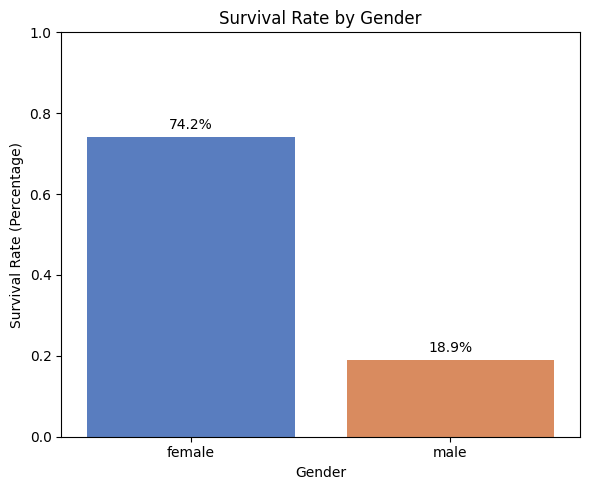

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate survival rate by gender
survival_by_gender = df.groupby('Sex')['Survived'].mean().reset_index()
print("Survival Rate by Gender:")
print(survival_by_gender)

# Create the bar plot
plt.figure(figsize=(6, 5))
sns.barplot(x='Sex', y='Survived', data=survival_by_gender, palette='muted', hue='Sex', legend=False)
plt.title('Survival Rate by Gender')
plt.ylabel('Survival Rate (Percentage)')
plt.xlabel('Gender')
plt.ylim(0, 1)  # Set limit from 0% to 100%

# Add percentage labels on top of the bars
for index, row in survival_by_gender.iterrows():
    plt.text(index, row['Survived'] + 0.02, f"{row['Survived']*100:.1f}%", color='black', ha="center")

plt.tight_layout()
plt.show()

## 6. Survival Rate by Ticket Class (Pclass)
Let's calculate and visualize the survival rate comparing passengers across different ticket classes (1st class, 2nd class, and 3rd class).

Survival Rate by Passenger Class (Pclass):
   Pclass  Survived
0       1  0.629630
1       2  0.472826
2       3  0.242363


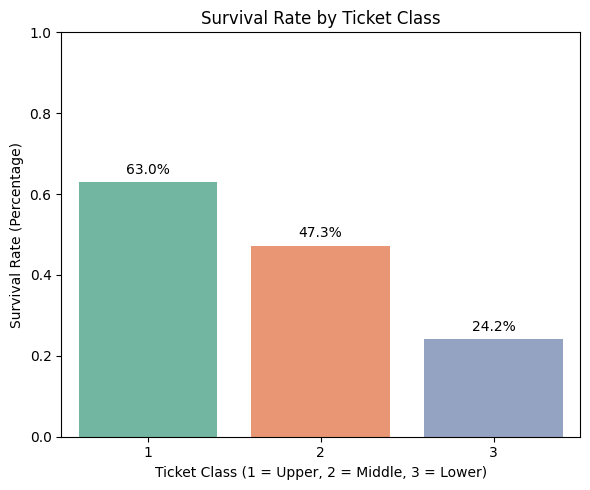

In [17]:
# Calculate survival rate by passenger class
survival_by_class = df.groupby('Pclass')['Survived'].mean().reset_index()
print("Survival Rate by Passenger Class (Pclass):")
print(survival_by_class)

# Create the bar plot
plt.figure(figsize=(6, 5))
sns.barplot(x='Pclass', y='Survived', data=survival_by_class, palette='Set2', hue='Pclass', legend=False)
plt.title('Survival Rate by Ticket Class')
plt.ylabel('Survival Rate (Percentage)')
plt.xlabel('Ticket Class (1 = Upper, 2 = Middle, 3 = Lower)')
plt.ylim(0, 1)

# Add percentage labels on top of the bars
for index, row in survival_by_class.iterrows():
    plt.text(index, row['Survived'] + 0.02, f"{row['Survived']*100:.1f}%", color='black', ha="center")

plt.tight_layout()
plt.show()

## 7. Survival Distribution by Age
Let's plot a histogram of the passenger ages, separated by survival status, to see if younger or older passengers had higher chances of survival.

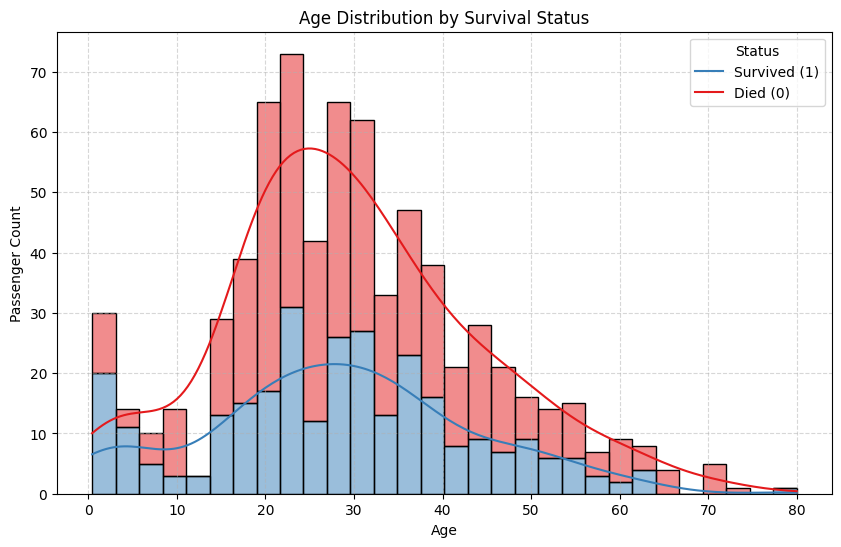

In [18]:
plt.figure(figsize=(10, 6))

# Plot overlapping histograms for those who survived and those who died
sns.histplot(data=df, x='Age', hue='Survived', multiple='stack', kde=True, palette='Set1', bins=30)

plt.title('Age Distribution by Survival Status')
plt.xlabel('Age')
plt.ylabel('Passenger Count')
plt.legend(title='Status', labels=['Survived (1)', 'Died (0)'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 8. Survival Rate by Gender and Ticket Class Combined
Let's analyze how gender and social class interacted to affect survival rates.

Survival Rate by Gender and Class:


,Sex,Pclass,Survived
0,female,1,0.968085
1,female,2,0.921053
2,female,3,0.500000
3,male,1,0.368852
4,male,2,0.157407
5,male,3,0.135447


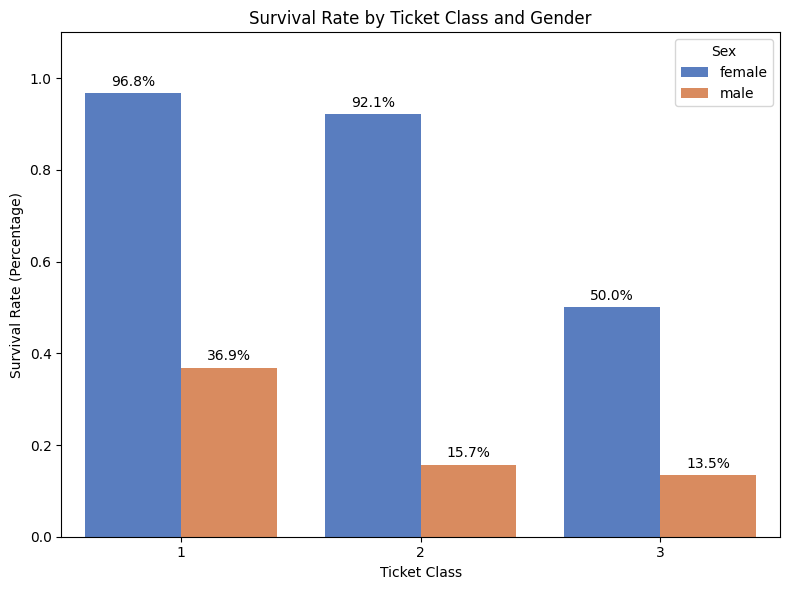

In [19]:
# Calculate survival rate grouped by Sex and Pclass
survival_gender_class = df.groupby(['Sex', 'Pclass'])['Survived'].mean().reset_index()
print("Survival Rate by Gender and Class:")
display(survival_gender_class)

# Create a grouped bar chart
plt.figure(figsize=(8, 6))
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=survival_gender_class, palette='muted')
plt.title('Survival Rate by Ticket Class and Gender')
plt.ylabel('Survival Rate (Percentage)')
plt.xlabel('Ticket Class')
plt.ylim(0, 1.1)

# Add percentage labels over the bars
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f"{height*100:.1f}%",
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='center',
                            xytext=(0, 8),
                            textcoords='offset points')

plt.tight_layout()
plt.show()